## Exercises
1) Keras offers the possibility to call a function at each epoch. These are Callbacks, and their [documentation is here](https://keras.io/callbacks/). Callbacks allow us to add some neat functionality. In this exercise, we'll explore a few of them.

- build a deep fully connected network with the following structure:
    - Input Layer: 784 nodes
    - Hidden Layer 1: 200 nodes
    - Hidden Layer 2: 100 nodes
    - Output Layer: 10 nodes
- choose activation functions, initializations, optimizer, learning rate and batch size so that it best converges to 100% accuracy (training and validation dataset) within 20 epochs (not easy)
- remember to train the model on the scaled data
- train the model on the train data using `validation_data=0.1`
- Use the `EarlyStopping` callback to stop your training if the `val_loss` doesn't improve
- Use the `ModelCheckpoint` callback to save the trained model to disk once training is over

2) Monte um banco de dados com 50 amostras de dígitos feitos no papel branco com caneta marcadora preto, escritos por 5 pessoas distintas. Fotografe as amostras e retrabalhe a imagem, retirando somente a área do dígito e deixando-a no formato quadrado 500x500 pixels. Teste as predições do seu banco de testes com a rede em sua melhor configuração e sintonia. Tire suas conclusões.

In [3]:
# Importando as bibliotecas tradicionais
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

# Importando o dataset MNIST
from tensorflow.keras.datasets import mnist

# Bibliotecas do TensorFlow / Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import SGD

import tensorflow.keras.backend as K

In [4]:
# Carregando o dataset MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print('X_train:', X_train.shape)
print('y_train:', y_train.shape)
print('X_test:', X_test.shape)
print('y_test:', y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
X_train: (60000, 28, 28)
y_train: (60000,)
X_test: (10000, 28, 28)
y_test: (10000,)


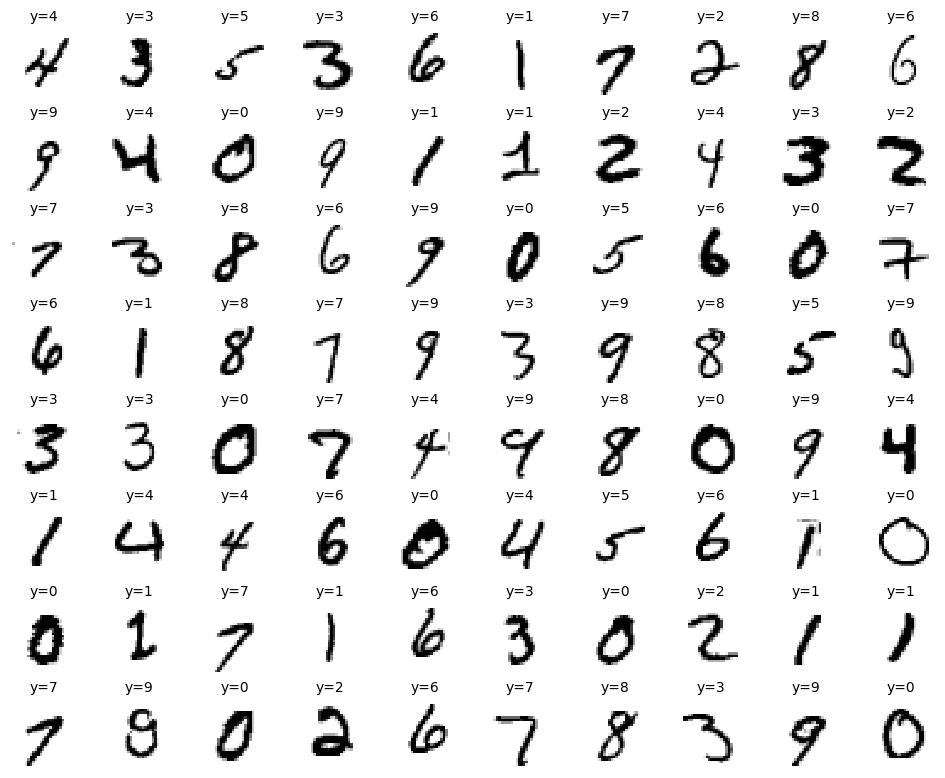

In [5]:
# Visualização de parte do dataset

class_names = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"]

n_rows = 8
n_cols = 10

rand = np.random.randint(100)

plt.figure(figsize=(n_cols * 1.2, n_rows * 1.2))

for row in range(n_rows):
    for col in range(n_cols):

        index = n_cols * row + col

        plt.subplot(n_rows, n_cols, index + 1)

        plt.imshow(
            X_train[index + rand],
            cmap="binary",
            interpolation="nearest"
        )

        plt.axis('off')

        plt.title(
            'y=' + class_names[y_train[index + rand]],
            fontsize=10
        )

plt.subplots_adjust(wspace=0.3, hspace=0.4)
plt.show()

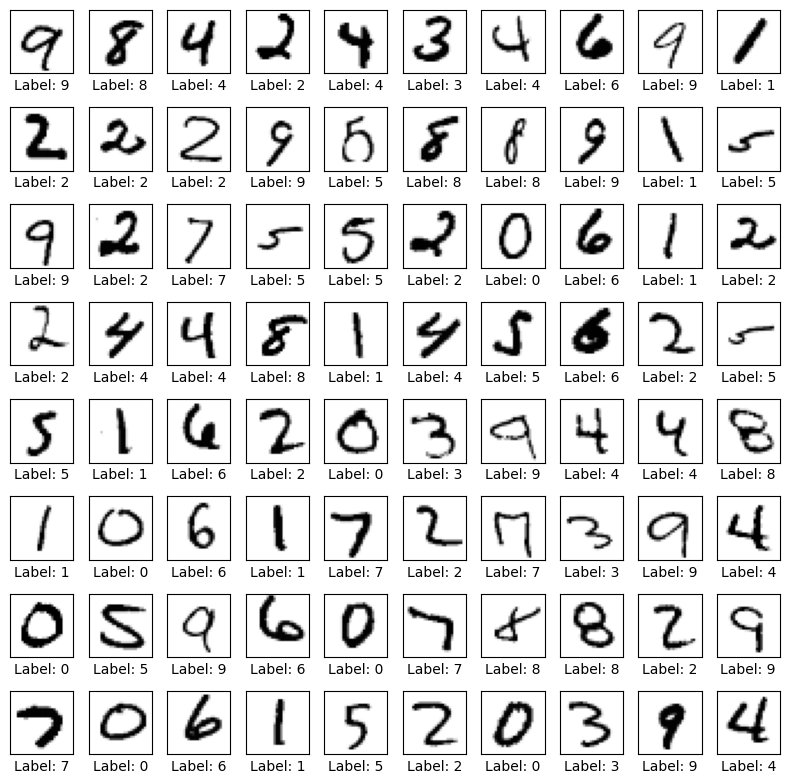

In [6]:
# Função para visualizar os dados

def show_data(examples, targets):

    samples = 80

    rand_num = np.random.randint(
        0,
        examples.shape[0] - samples
    )

    plt.figure(figsize=(8, 8))

    for i in range(samples):

        plt.subplot(8, 10, i + 1)

        plt.imshow(
            examples[rand_num + i],
            cmap='Greys'
        )

        plt.xlabel(
            f"Label: {targets[rand_num + i]}"
        )

        plt.xticks([])
        plt.yticks([])

    plt.tight_layout()
    plt.show()


# Mostrar 80 amostras
show_data(X_train, y_train)

In [7]:
# Redução da dimensão de 28x28 para 784

X_train_flat = X_train.reshape(60000, 784)

X_test_flat = X_test.reshape(-1, 28 * 28)

print('X_train_flat:', X_train_flat.shape)


X_train_flat: (60000, 784)


In [8]:
# Normalização dos pixels

max_value = X_train.max()

print('Valor máximo do pixel:', max_value)

X_train_sc = X_train_flat / max_value
X_test_sc = X_test_flat / max_value

print(
    'Valor mínimo após normalização:',
    X_train_sc.min()
)

print(
    'Valor máximo após normalização:',
    X_train_sc.max()
)

Valor máximo do pixel: 255
Valor mínimo após normalização: 0.0
Valor máximo após normalização: 1.0


In [9]:
# Inicializando a sessão
K.clear_session()

# Criando o modelo
model = Sequential(name='rede1')

# Camada de entrada
model.add(
    Input(
        shape=(784,),
        name='input'
    )
)

# Hidden Layer
model.add(
    Dense(
        units=50,
        activation='relu',
        name='layer1'
    )
)

# Camada de saída
model.add(
    Dense(
        10,
        activation='softmax',
        name='output'
    )
)

# Visualização da arquitetura
model.summary()

Model: "rede1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 50)             │        39,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 39,760 (155.31 KB)

 Trainable params: 39,760 (155.31 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Learning rate
eta = 0.01

# Otimizador SGD
optimizer = SGD(
    learning_rate=eta
)

# Compilando o modelo
model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Salvando os pesos iniciais
weights = model.get_weights()

In [11]:
# Início da contagem do tempo
start_time = time.process_time()

# Restaurando os pesos iniciais
model.set_weights(weights)

# Treinamento
h = model.fit(
    X_train_sc,
    y_train,
    batch_size=128,
    epochs=10,
    verbose=1,
    validation_split=0.1
)

# Tempo de treinamento
training_time_s = time.process_time() - start_time
training_time_m = training_time_s / 60

print(
    "\nTempo de treinamento: "
    "%.2f segundos (%.2f minutos)"
    % (training_time_s, training_time_m)
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6476 - loss: 1.3830 - val_accuracy: 0.8668 - val_loss: 0.7254
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8506 - loss: 0.6389 - val_accuracy: 0.8980 - val_loss: 0.4559
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8758 - loss: 0.4873 - val_accuracy: 0.9063 - val_loss: 0.3724
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8872 - loss: 0.4252 - val_accuracy: 0.9140 - val_loss: 0.3314
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8940 - loss: 0.3898 - val_accuracy: 0.9182 - val_loss: 0.3067
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8998 - loss: 0.3661 - val_accuracy: 0.9213 - val_loss: 0.2901
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9032 - loss: 0.3488 - val_accuracy: 0.9240 - val_loss: 0.2772
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9066 - loss: 0.3350 - val_accuracy: 0.

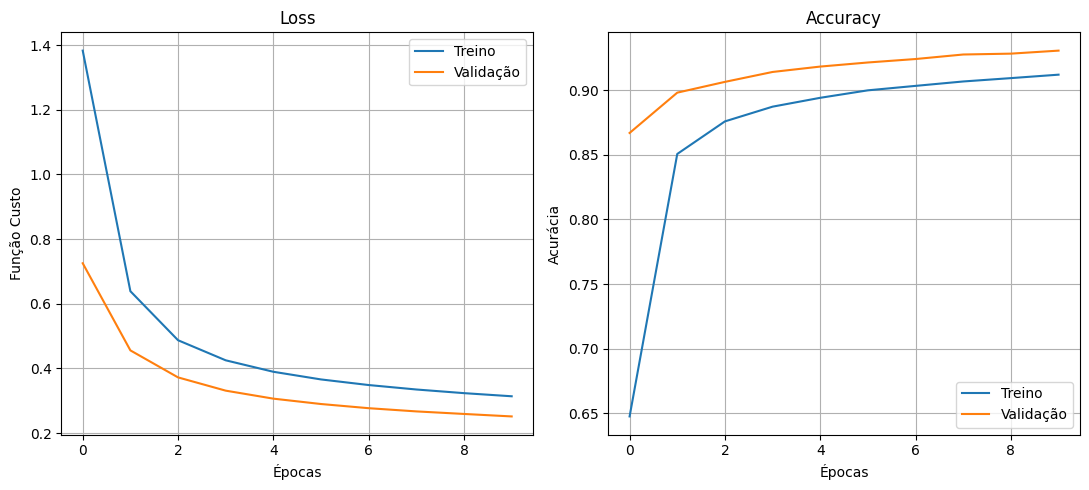

In [12]:
# Gráficos de Loss e Accuracy

plt.figure(figsize=(11, 5))

# Loss
plt.subplot(1, 2, 1)

plt.plot(
    h.history['loss'],
    label='Treino'
)

plt.plot(
    h.history['val_loss'],
    label='Validação'
)

plt.xlabel('Épocas')
plt.ylabel('Função Custo')
plt.title('Loss')

plt.legend()
plt.grid()


# Accuracy
plt.subplot(1, 2, 2)

plt.plot(
    h.history['accuracy'],
    label='Treino'
)

plt.plot(
    h.history['val_accuracy'],
    label='Validação'
)

plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.title('Accuracy')

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [13]:
# Testando diferentes Learning Rates

learning_rates = [0.01, 0.05, 0.1, 0.5]

dflist = []

for lr in learning_rates:

    print("Learning Rate:", lr)

    # Compilando o modelo
    model.compile(
        optimizer=SGD(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # Restaurando os pesos iniciais
    model.set_weights(weights)

    # Treinamento
    h = model.fit(
        X_train_sc,
        y_train,
        batch_size=128,
        epochs=10,
        verbose=0,
        validation_split=0.1
    )

    # Salvando os resultados
    dflist.append(
        pd.DataFrame(
            h.history,
            index=h.epoch
        )
    )

    print("Done:", lr)

Learning Rate: 0.01
Done: 0.01
Learning Rate: 0.05
Done: 0.05
Learning Rate: 0.1
Done: 0.1
Learning Rate: 0.5
Done: 0.5


In [14]:
# Juntando os resultados

historydf = pd.concat(
    dflist,
    axis=1
)

metrics_reported = dflist[0].columns

idx = pd.MultiIndex.from_product(
    [learning_rates, metrics_reported],
    names=['learning_rate', 'metric']
)

historydf.columns = idx

historydf

learning_rate      0.01                                       0.05            \
metric         accuracy      loss val_accuracy  val_loss  accuracy      loss   
0              0.646278  1.384281     0.865833  0.726084  0.826741  0.672850   
1              0.850537  0.638814     0.900333  0.455641  0.904574  0.343323   
2              0.874833  0.487232     0.908167  0.372231  0.916333  0.297701   
3              0.887167  0.425278     0.914333  0.331864  0.924426  0.269182   
4              0.894204  0.390084     0.918167  0.308135  0.930796  0.246767   
5              0.899407  0.366548     0.922333  0.290542  0.936148  0.228145   
6              0.903500  0.349177     0.923833  0.277833  0.940296  0.211745   
7              0.906222  0.335389     0.927000  0.267375  0.944333  0.198078   
8              0.909426  0.324159     0.928167  0.259583  0.948000  0.186091   
9              0.911759  0.314567     0.929500  0.252206  0.950778  0.175463   

learning_rate                             0.10                         \
metric        val_accuracy  val_loss  accuracy      loss val_accuracy   
0                 0.917500  0.308447  0.860148  0.517766     0.929167   
1                 0.930833  0.253576  0.919056  0.288688     0.940167   
2                 0.936000  0.227919  0.932981  0.240811     0.953500   
3                 0.940833  0.211904  0.941222  0.208400     0.956667   
4                 0.948833  0.192958  0.948204  0.183896     0.962167   
5                 0.952833  0.181952  0.953241  0.164704     0.962500   
6                 0.955500  0.172566  0.957352  0.150822     0.964000   
7                 0.958000  0.161107  0.960685  0.138781     0.966333   
8                 0.960000  0.152133  0.963296  0.128507     0.970500   
9                 0.961167  0.146142  0.965648  0.119771     0.970500   

learning_rate                0.50                                   
metric         val_loss  accuracy      loss val_accuracy  val_loss  
0              0.256429  0.895778  0.345506     0.957500  0.147882  
1              0.215265  0.953407  0.158944     0.965000  0.118600  
2              0.180141  0.964185  0.119878     0.966333  0.117984  
3              0.164947  0.970130  0.099352     0.971500  0.093703  
4              0.144509  0.974519  0.083721     0.974833  0.089941  
5              0.140762  0.976981  0.074050     0.976667  0.085767  
6              0.131534  0.980000  0.065127     0.972667  0.089772  
7              0.124572  0.982648  0.057622     0.974833  0.088328  
8              0.113068  0.983407  0.053306     0.976167  0.085861  
9              0.111314  0.986222  0.046310     0.976333  0.085895

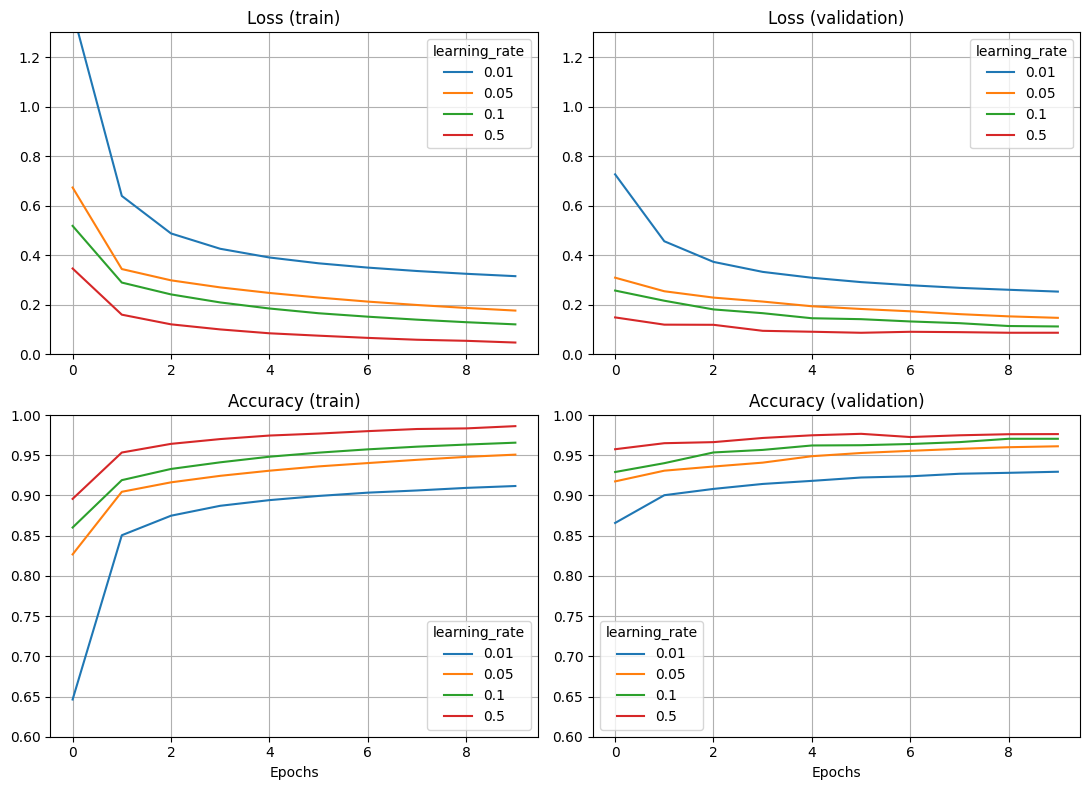

In [15]:
# Gráficos dos diferentes Learning Rates

plt.figure(figsize=(11, 8))

# Loss - treinamento
ax = plt.subplot(2, 2, 1)

historydf.xs(
    'loss',
    axis=1,
    level='metric'
).plot(
    ylim=(0, 1.3),
    ax=ax
)

plt.title("Loss (train)")
plt.grid()


# Loss - validação
ax = plt.subplot(2, 2, 2)

historydf.xs(
    'val_loss',
    axis=1,
    level='metric'
).plot(
    ylim=(0, 1.3),
    ax=ax
)

plt.title("Loss (validation)")
plt.grid()


# Accuracy - treinamento
ax = plt.subplot(2, 2, 3)

historydf.xs(
    'accuracy',
    axis=1,
    level='metric'
).plot(
    ylim=(0.6, 1),
    ax=ax
)

plt.title("Accuracy (train)")
plt.xlabel("Epochs")
plt.grid()


# Accuracy - validação
ax = plt.subplot(2, 2, 4)

historydf.xs(
    'val_accuracy',
    axis=1,
    level='metric'
).plot(
    ylim=(0.6, 1),
    ax=ax
)

plt.title("Accuracy (validation)")
plt.xlabel("Epochs")
plt.grid()

plt.tight_layout()
plt.show()

In [16]:
# Testando diferentes Batch Sizes

batch_sizes = [16, 32, 64, 128, 256]

# Learning Rate utilizado
lr = 0.5

dflist = []

# Compilando o modelo
model.compile(
    optimizer=SGD(learning_rate=lr),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

for batch_size in batch_sizes:

    print("Batch Size:", batch_size)

    # Restaurando os pesos
    model.set_weights(weights)

    # Treinamento
    h = model.fit(
        X_train_sc,
        y_train,
        batch_size=batch_size,
        epochs=10,
        verbose=0,
        validation_split=0.1
    )

    # Salvando resultados
    dflist.append(
        pd.DataFrame(
            h.history,
            index=h.epoch
        )
    )

    print("Done:", batch_size)

Batch Size: 16
Done: 16
Batch Size: 32
Done: 32
Batch Size: 64
Done: 64
Batch Size: 128
Done: 128
Batch Size: 256
Done: 256


In [17]:
# Organizando os resultados

historydf = pd.concat(
    dflist,
    axis=1
)

metrics_reported = dflist[0].columns

idx = pd.MultiIndex.from_product(
    [batch_sizes, metrics_reported],
    names=['batch_size', 'metric']
)

historydf.columns = idx

historydf

batch_size       16                                         32             \
metric      accuracy      loss val_accuracy  val_loss  accuracy      loss   
0           0.898852  0.348298     0.949333  0.200613  0.909630  0.294859   
1           0.937704  0.225347     0.947167  0.177101  0.953278  0.151220   
2           0.947926  0.188684     0.956833  0.175824  0.962926  0.122774   
3           0.952944  0.177469     0.948667  0.222545  0.966833  0.108362   
4           0.956389  0.166806     0.960833  0.169462  0.970444  0.098486   
5           0.958352  0.162703     0.955167  0.212558  0.972259  0.088347   
6           0.960352  0.153675     0.955500  0.214655  0.975667  0.081221   
7           0.961852  0.154723     0.949000  0.249668  0.976093  0.076997   
8           0.964241  0.143176     0.956500  0.214680  0.978667  0.067412   
9           0.965130  0.137903     0.960333  0.195592  0.979037  0.068254   

batch_size                              64                                    \
metric     val_accuracy  val_loss  accuracy      loss val_accuracy  val_loss   
0              0.961167  0.139361  0.908259  0.295934     0.964333  0.128685   
1              0.965333  0.119039  0.957722  0.140690     0.967000  0.112872   
2              0.968667  0.115013  0.966611  0.109561     0.971500  0.104378   
3              0.972500  0.110008  0.971519  0.091001     0.976000  0.090461   
4              0.952167  0.171850  0.975056  0.079642     0.970000  0.104283   
5              0.971333  0.110493  0.978648  0.068399     0.973667  0.090751   
6              0.968000  0.125540  0.980778  0.061344     0.972167  0.103196   
7              0.964833  0.147509  0.982481  0.054828     0.971167  0.107059   
8              0.966667  0.144848  0.984907  0.048539     0.975000  0.093911   
9              0.952833  0.192469  0.984648  0.045754     0.971333  0.113275   

batch_size       128                                        256            \
metric      accuracy      loss val_accuracy  val_loss  accuracy      loss   
0           0.894518  0.342744     0.955500  0.151844  0.866593  0.441469   
1           0.952611  0.158229     0.958667  0.137397  0.939778  0.206726   
2           0.963500  0.120911     0.972000  0.099774  0.952648  0.162197   
3           0.969241  0.099777     0.967500  0.114329  0.960926  0.134715   
4           0.973463  0.087470     0.972833  0.096784  0.966222  0.116062   
5           0.977278  0.075865     0.974500  0.089106  0.969259  0.102974   
6           0.978833  0.067977     0.974167  0.090822  0.973537  0.092291   
7           0.981315  0.060175     0.971500  0.100733  0.975444  0.083520   
8           0.982759  0.055626     0.977833  0.084867  0.977796  0.077166   
9           0.984519  0.050563     0.973500  0.099612  0.978759  0.071574   

batch_size                         
metric     val_accuracy  val_loss  
0              0.941000  0.200040  
1              0.956167  0.149804  
2              0.962833  0.130562  
3              0.969167  0.108524  
4              0.969833  0.112139  
5              0.971000  0.108528  
6              0.971000  0.101543  
7              0.972000  0.098843  
8              0.971500  0.103231  
9              0.973667  0.091490

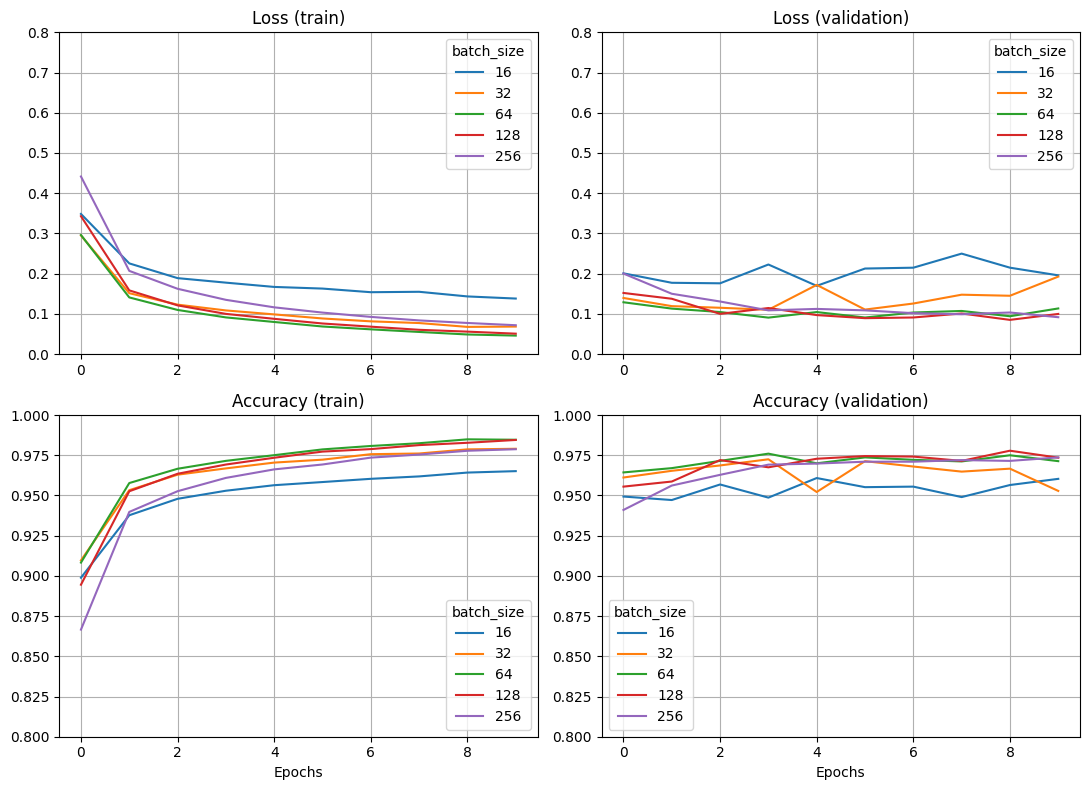

In [18]:
# Gráficos dos diferentes Batch Sizes

plt.figure(figsize=(11, 8))

# Loss - treinamento
ax = plt.subplot(2, 2, 1)

historydf.xs(
    'loss',
    axis=1,
    level='metric'
).plot(
    ylim=(0, 0.8),
    ax=ax
)

plt.title("Loss (train)")
plt.grid()


# Loss - validação
ax = plt.subplot(2, 2, 2)

historydf.xs(
    'val_loss',
    axis=1,
    level='metric'
).plot(
    ylim=(0, 0.8),
    ax=ax
)

plt.title("Loss (validation)")
plt.grid()


# Accuracy - treinamento
ax = plt.subplot(2, 2, 3)

historydf.xs(
    'accuracy',
    axis=1,
    level='metric'
).plot(
    ylim=(0.8, 1),
    ax=ax
)

plt.title("Accuracy (train)")
plt.xlabel("Epochs")
plt.grid()


# Accuracy - validação
ax = plt.subplot(2, 2, 4)

historydf.xs(
    'val_accuracy',
    axis=1,
    level='metric'
).plot(
    ylim=(0.8, 1),
    ax=ax
)

plt.title("Accuracy (validation)")
plt.xlabel("Epochs")
plt.grid()

plt.tight_layout()
plt.show()

In [19]:
# Importando os otimizadores

from tensorflow.keras.optimizers import (
    SGD,
    Adam,
    Adagrad,
    RMSprop,
    Adadelta
)

In [20]:
# Diferentes configurações de otimizadores

opts = [
    SGD(learning_rate=0.5),
    SGD(learning_rate=0.5, momentum=0.3),
    SGD(learning_rate=0.5, momentum=0.3, nesterov=True),
    Adam(learning_rate=0.5),
    Adagrad(learning_rate=0.5),
    RMSprop(learning_rate=0.5),
    Adadelta(learning_rate=0.5)
]

optimizer_names = [
    'SGD',
    'SGD + Momentum',
    'SGD + Nesterov',
    'Adam',
    'Adagrad',
    'RMSprop',
    'Adadelta'
]

dflist = []

for optimizer, name in zip(opts, optimizer_names):

    print("Otimizador:", name)

    # Compilando
    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # Restaurando pesos
    model.set_weights(weights)

    # Treinamento
    h = model.fit(
        X_train_sc,
        y_train,
        batch_size=64,
        epochs=10,
        verbose=0,
        validation_split=0.1
    )

    dflist.append(
        pd.DataFrame(
            h.history,
            index=h.epoch
        )
    )

    print("Done:", name)

Otimizador: SGD
Done: SGD
Otimizador: SGD + Momentum
Done: SGD + Momentum
Otimizador: SGD + Nesterov
Done: SGD + Nesterov
Otimizador: Adam
Done: Adam
Otimizador: Adagrad
Done: Adagrad
Otimizador: RMSprop
Done: RMSprop
Otimizador: Adadelta
Done: Adadelta


In [21]:
# Organizando os resultados

historydf = pd.concat(
    dflist,
    axis=1
)

metrics_reported = dflist[0].columns

idx = pd.MultiIndex.from_product(
    [optimizer_names, metrics_reported],
    names=['optimizer', 'metric']
)

historydf.columns = idx

historydf

optimizer       SGD                                  SGD + Momentum            \
metric     accuracy      loss val_accuracy  val_loss       accuracy      loss   
0          0.910333  0.296916     0.958000  0.137652       0.913185  0.283908   
1          0.958130  0.139203     0.969333  0.105429       0.954278  0.147604   
2          0.968019  0.106987     0.966667  0.106972       0.965130  0.114048   
3          0.972630  0.088916     0.971000  0.098261       0.970463  0.095990   
4          0.976185  0.075313     0.963833  0.112700       0.972593  0.087277   
5          0.978704  0.066654     0.969333  0.104002       0.975630  0.076478   
6          0.981130  0.059578     0.974500  0.093504       0.978407  0.068725   
7          0.982796  0.052456     0.969500  0.117449       0.979296  0.062527   
8          0.983722  0.048837     0.974167  0.102471       0.980482  0.058373   
9          0.985296  0.044681     0.973667  0.100605       0.983259  0.051799   

optimizer                        SGD + Nesterov            ...      Adagrad  \
metric    val_accuracy  val_loss       accuracy      loss  ... val_accuracy   
0             0.954167  0.145833       0.891537  0.350905  ...     0.927333   
1             0.970333  0.102938       0.947463  0.177297  ...     0.934333   
2             0.971000  0.105049       0.956722  0.147473  ...     0.944833   
3             0.963333  0.122443       0.961296  0.127109  ...     0.944500   
4             0.973667  0.101414       0.964648  0.115273  ...     0.954167   
5             0.975000  0.091310       0.968574  0.103805  ...     0.955000   
6             0.974167  0.092917       0.969907  0.097661  ...     0.957333   
7             0.971833  0.110209       0.973222  0.089000  ...     0.957167   
8             0.971833  0.122589       0.973630  0.085819  ...     0.958667   
9             0.973000  0.110204       0.975148  0.077794  ...     0.958667   

optimizer             RMSprop                                   Adadelta  \
metric     val_loss  accuracy      loss val_accuracy  val_loss  accuracy   
0          0.266960  0.156389  7.306549     0.158500  2.237403  0.875315   
1          0.217196  0.161963  2.289700     0.181167  2.230844  0.930796   
2          0.195795  0.175852  2.242213     0.150667  2.324472  0.943315   
3          0.191612  0.177519  2.214951     0.207167  2.182403  0.951000   
4          0.153828  0.174852  2.218298     0.178833  2.134274  0.956574   
5          0.155203  0.183037  2.250814     0.201500  2.073692  0.961130   
6          0.145823  0.190370  2.199125     0.194833  2.230511  0.964556   
7          0.156497  0.183185  2.230892     0.189667  2.184088  0.968259   
8          0.149525  0.189815  2.190849     0.188333  2.363095  0.970333   
9          0.145137  0.188019  2.211306     0.201667  2.098169  0.972481   

optimizer                                   
metric         loss val_accuracy  val_loss  
0          0.462589     0.937500  0.224225  
1          0.248059     0.952167  0.178613  
2          0.201810     0.960333  0.153641  
3          0.172237     0.963500  0.136033  
4          0.150851     0.967167  0.123748  
5          0.135196     0.966333  0.120530  
6          0.123155     0.970167  0.110456  
7          0.113058     0.971000  0.108647  
8          0.105103     0.971333  0.102350  
9          0.098149     0.973167  0.102000  

[10 rows x 28 columns]

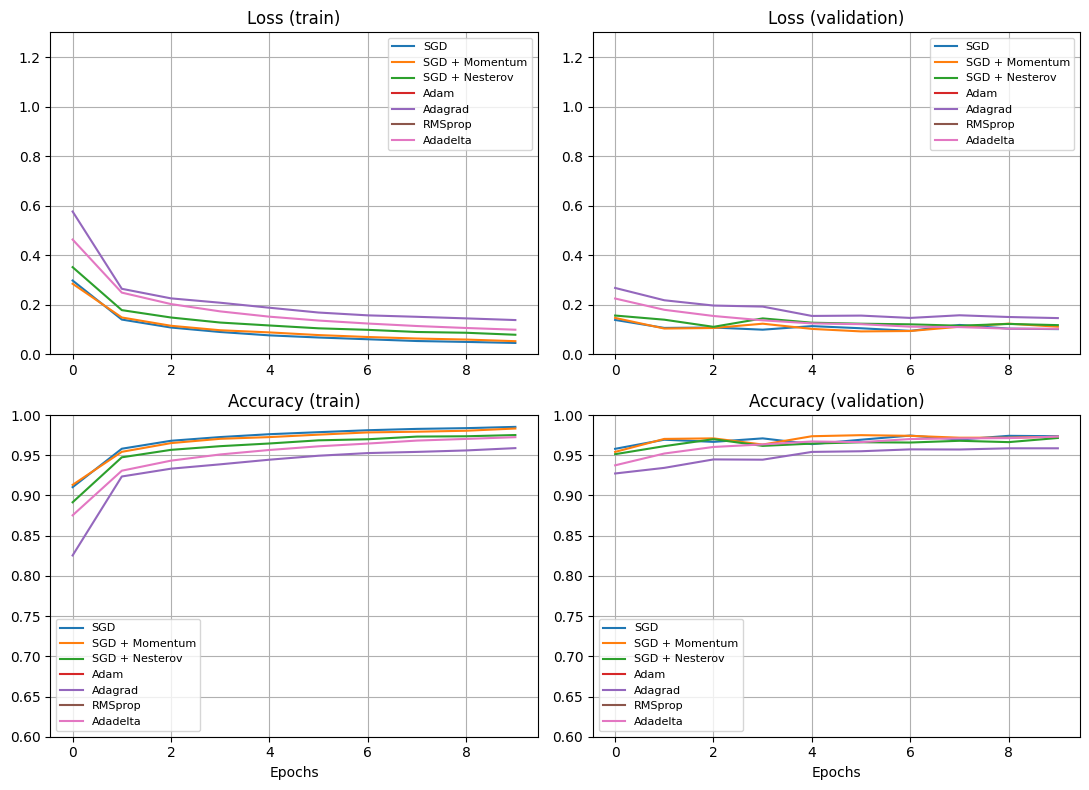

In [22]:
# Comparação dos otimizadores

plt.figure(figsize=(11, 8))

# Loss - treinamento
ax = plt.subplot(2, 2, 1)

historydf.xs(
    'loss',
    axis=1,
    level='metric'
).plot(
    ylim=(0, 1.3),
    ax=ax
)

plt.title("Loss (train)")
plt.legend(fontsize=8)
plt.grid()


# Loss - validação
ax = plt.subplot(2, 2, 2)

historydf.xs(
    'val_loss',
    axis=1,
    level='metric'
).plot(
    ylim=(0, 1.3),
    ax=ax
)

plt.title("Loss (validation)")
plt.legend(fontsize=8)
plt.grid()


# Accuracy - treinamento
ax = plt.subplot(2, 2, 3)

historydf.xs(
    'accuracy',
    axis=1,
    level='metric'
).plot(
    ylim=(0.6, 1),
    ax=ax
)

plt.title("Accuracy (train)")
plt.xlabel("Epochs")
plt.legend(fontsize=8)
plt.grid()


# Accuracy - validação
ax = plt.subplot(2, 2, 4)

historydf.xs(
    'val_accuracy',
    axis=1,
    level='metric'
).plot(
    ylim=(0.6, 1),
    ax=ax
)

plt.title("Accuracy (validation)")
plt.xlabel("Epochs")
plt.legend(fontsize=8)
plt.grid()

plt.tight_layout()
plt.show()

In [23]:
# Diferentes formas de inicialização

inits = [
    'zeros',
    'ones',
    'uniform',
    'lecun_uniform',
    'normal',
    'he_normal',
    'glorot_normal'
]

dflist = []

for init in inits:

    print("Inicialização:", init)

    # Limpa a sessão
    K.clear_session()

    # Cria um novo modelo
    model = Sequential()

    # Entrada
    model.add(
        Input(shape=(784,))
    )

    # Camada oculta
    model.add(
        Dense(
            units=50,
            activation='relu',
            kernel_initializer=init
        )
    )

    # Saída
    model.add(
        Dense(
            10,
            activation='softmax',
            kernel_initializer=init
        )
    )

    # Compilação
    model.compile(
        optimizer='sgd',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # Treinamento
    h = model.fit(
        X_train_sc,
        y_train,
        batch_size=64,
        epochs=10,
        verbose=0,
        validation_split=0.1
    )

    # Salvar resultados
    dflist.append(
        pd.DataFrame(
            h.history,
            index=h.epoch
        )
    )

    print("Done:", init)

Inicialização: zeros
Done: zeros
Inicialização: ones
Done: ones
Inicialização: uniform
Done: uniform
Inicialização: lecun_uniform
Done: lecun_uniform
Inicialização: normal
Done: normal
Inicialização: he_normal
Done: he_normal
Inicialização: glorot_normal
Done: glorot_normal


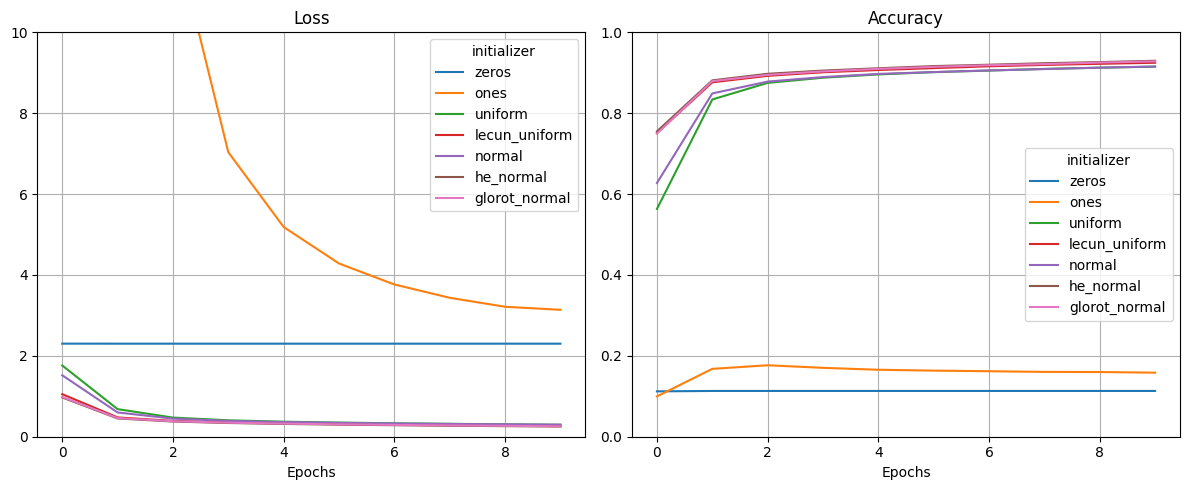

In [25]:
# Organizando os resultados

historydf = pd.concat(
    dflist,
    axis=1
)

metrics_reported = dflist[0].columns

idx = pd.MultiIndex.from_product(
    [inits, metrics_reported],
    names=['initializer', 'metric']
)

historydf.columns = idx

# Gráficos

plt.figure(figsize=(12, 5))

# Loss
ax = plt.subplot(1, 2, 1)

historydf.xs(
    'loss',
    axis=1,
    level='metric'
).plot(
    ylim=(0, 10),
    ax=ax
)

plt.title("Loss")
plt.xlabel("Epochs")
plt.grid()


# Accuracy
ax = plt.subplot(1, 2, 2)

historydf.xs(
    'accuracy',
    axis=1,
    level='metric'
).plot(
    ylim=(0, 1),
    ax=ax
)

plt.title("Accuracy")
plt.xlabel("Epochs")
plt.grid()

plt.tight_layout()
plt.show()

In [26]:
# Fazendo as predições

prediction = model.predict(X_test_sc)

# Escolhendo uma amostra
amostra = 150

print(
    'Predição da amostra:',
    prediction[amostra]
)

print(
    'Soma dos valores:',
    prediction[amostra].sum()
)

print(
    'Posição do maior valor:',
    prediction[amostra].argmax()
)

print(
    'Probabilidade de acerto: %.3f%%'
    % (prediction[amostra].max() * 100)
)

print(
    'Label real:',
    y_test[amostra]
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Predição da amostra: [1.0487570e-04 3.0370963e-06 1.4220554e-03 1.7169017e-03 5.7164248e-02
 8.0905441e-04 3.2055716e-04 8.7241572e-04 7.1130381e-03 9.3047386e-01]
Soma dos valores: 1.0
Posição do maior valor: 9
Probabilidade de acerto: 93.047%
Label real: 9


In [27]:
# Obtendo a classe com maior probabilidade

y_predict = np.argmax(
    prediction,
    axis=1
)

print(y_predict)

[7 2 1 ... 4 5 6]


In [28]:
from sklearn.metrics import confusion_matrix

# Criando a matriz de confusão

confusion = confusion_matrix(
    y_test,
    y_predict
)

print(confusion)

[[ 959    0    0    3    0    4    9    1    4    0]
 [   0 1106    1    4    1    1    3    2   17    0]
 [  13    3  940   10   11    1   10   15   27    2]
 [   3    0   18  936    0   18    3   13   16    3]
 [   2    2    5    0  921    0   10    2    6   34]
 [  10    2    3   35    6  791   16    3   18    8]
 [  15    3    6    0   12   12  907    1    2    0]
 [   2    7   25    4    7    0    0  959    4   20]
 [   5    4    6   21    7   16   12    9  886    8]
 [  13    7    2   11   32    7    0   14    3  920]]


In [32]:
import itertools

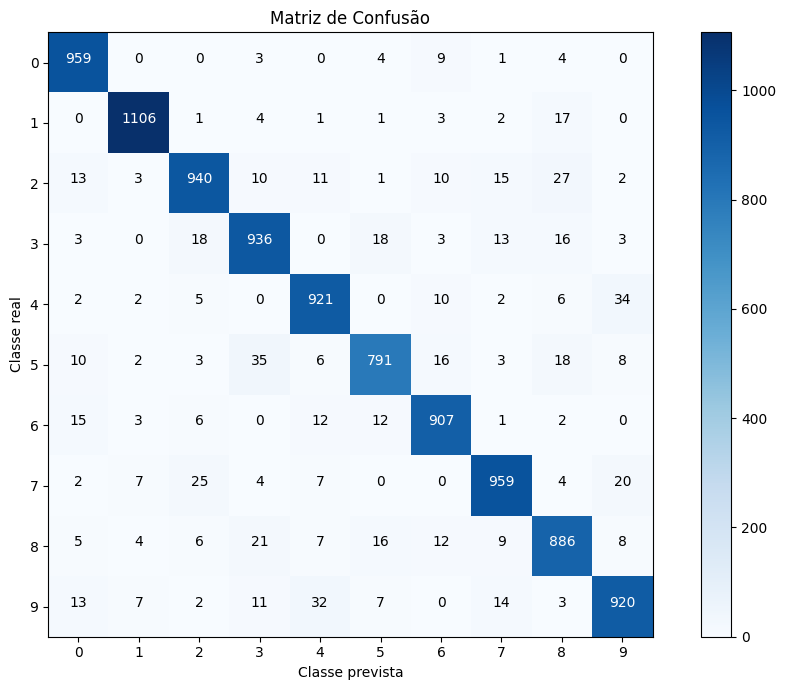

In [33]:
# Função para visualizar a matriz de confusão

def plot_confusion_matrix(
    cm,
    classes,
    normalize=False,
    title='Matriz de Confusão'
):

    if normalize:

        cm = cm.astype('float') / cm.sum(
            axis=1
        )[:, np.newaxis]

    plt.figure(figsize=(10, 7))

    plt.imshow(
        cm,
        interpolation='nearest',
        cmap=plt.cm.Blues
    )

    plt.title(title)
    plt.colorbar()

    tick_marks = np.arange(len(classes))

    plt.xticks(
        tick_marks,
        classes
    )

    plt.yticks(
        tick_marks,
        classes
    )

    thresh = cm.max() / 2

    for i, j in itertools.product(
        range(cm.shape[0]),
        range(cm.shape[1])
    ):

        plt.text(
            j,
            i,
            cm[i, j],
            horizontalalignment='center',
            color='white'
            if cm[i, j] > thresh
            else 'black'
        )

    plt.ylabel('Classe real')
    plt.xlabel('Classe prevista')

    plt.tight_layout()
    plt.show()


# Visualizar
plot_confusion_matrix(
    confusion,
    classes=range(10)
)

In [34]:
from sklearn.metrics import classification_report

# Relatório de classificação

print(
    classification_report(
        y_test,
        y_predict
    )
)

              precision    recall  f1-score   support

           0       0.94      0.98      0.96       980
           1       0.98      0.97      0.97      1135
           2       0.93      0.91      0.92      1032
           3       0.91      0.93      0.92      1010
           4       0.92      0.94      0.93       982
           5       0.93      0.89      0.91       892
           6       0.94      0.95      0.94       958
           7       0.94      0.93      0.94      1028
           8       0.90      0.91      0.91       974
           9       0.92      0.91      0.92      1009

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



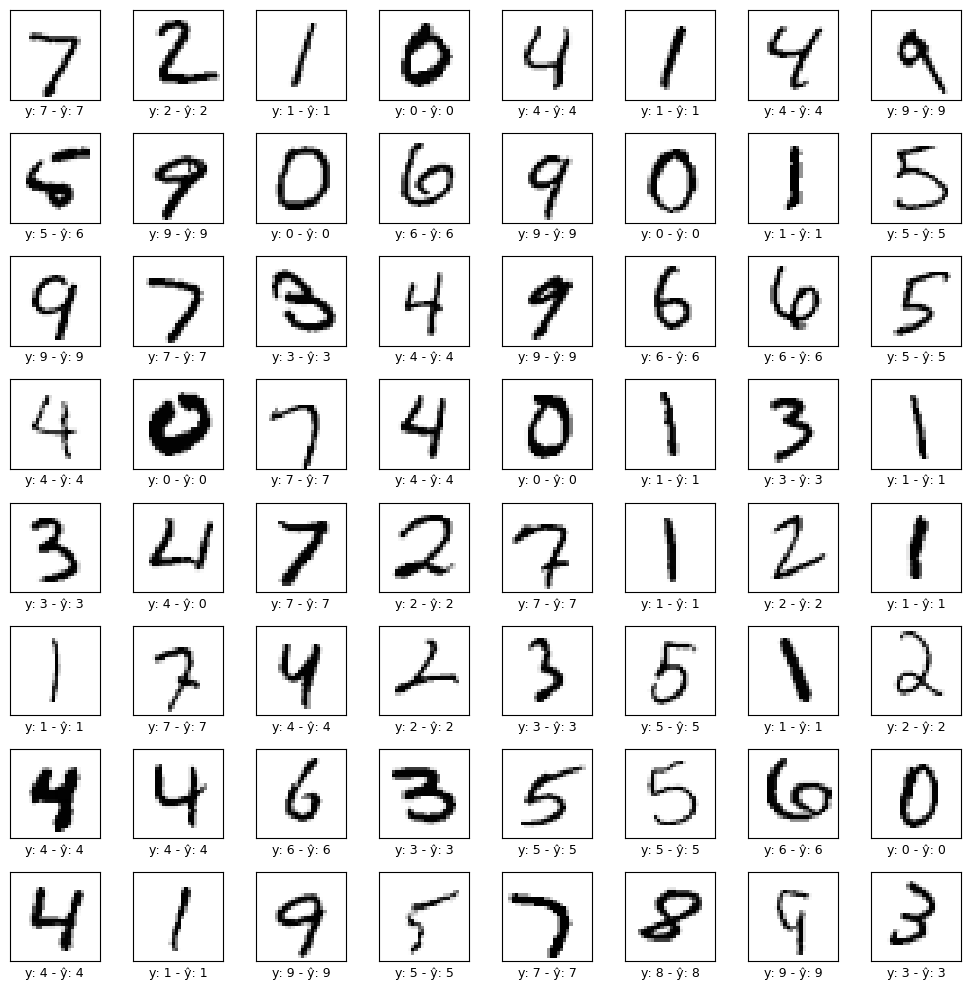

In [35]:
# Função para visualizar as predições

def show_predict(
    examples,
    targets,
    predictions
):

    plt.figure(figsize=(10, 10))

    for i in range(64):

        plt.subplot(8, 8, i + 1)

        plt.imshow(
            examples[i],
            cmap='Greys'
        )

        plt.xlabel(
            f'y: {targets[i]} - '
            f'ŷ: {predictions[i]}',
            size=9
        )

        plt.xticks([])
        plt.yticks([])

    plt.tight_layout()
    plt.show()


# Mostrar as primeiras 64 imagens
show_predict(
    X_test,
    y_test,
    y_predict
)

##Exercício 1.

In [36]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

In [37]:
# Criando uma rede neural mais profunda

K.clear_session()

deep_model = Sequential(
    name='rede_profunda'
)

# Camada de entrada
deep_model.add(
    Input(shape=(784,))
)

# Hidden Layer 1
deep_model.add(
    Dense(
        200,
        activation='relu',
        kernel_initializer='he_normal'
    )
)

# Hidden Layer 2
deep_model.add(
    Dense(
        100,
        activation='relu',
        kernel_initializer='he_normal'
    )
)

# Camada de saída
deep_model.add(
    Dense(
        10,
        activation='softmax'
    )
)

deep_model.summary()

Model: "rede_profunda"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 200)            │       157,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        20,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 178,110 (695.74 KB)

 Trainable params: 178,110 (695.74 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
# Compilando a rede

deep_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [39]:
# EarlyStopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# ModelCheckpoint
checkpoint = ModelCheckpoint(
    'melhor_modelo_mnist.keras',
    monitor='val_loss',
    save_best_only=True
)

In [40]:
# Treinamento da rede profunda

history_deep = deep_model.fit(
    X_train_sc,
    y_train,
    batch_size=64,
    epochs=20,
    validation_split=0.1,
    callbacks=[
        early_stop,
        checkpoint
    ],
    verbose=1
)

Epoch 1/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9245 - loss: 0.2544 - val_accuracy: 0.9713 - val_loss: 0.1045
Epoch 2/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9713 - loss: 0.0966 - val_accuracy: 0.9733 - val_loss: 0.0891
Epoch 3/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9803 - loss: 0.0653 - val_accuracy: 0.9790 - val_loss: 0.0730
Epoch 4/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9843 - loss: 0.0479 - val_accuracy: 0.9800 - val_loss: 0.0690
Epoch 5/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9884 - loss: 0.0361 - val_accuracy: 0.9830 - val_loss: 0.0679
Epoch 6/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9911 - loss: 0.0279 - val_accuracy: 0.9782 - val_loss: 0.0804
Epoch 7/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9917 - loss: 0.0241 - val_accuracy: 0.9788 - val_loss: 0.0772
Epoch 8/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9936 - loss: 0.0186 - val_accuracy: 0.

In [41]:
# Avaliando o modelo no conjunto de teste

test_loss, test_accuracy = deep_model.evaluate(
    X_test_sc,
    y_test,
    verbose=0
)

print(
    f'Acurácia no conjunto de teste: '
    f'{test_accuracy:.4f}'
)

Acurácia no conjunto de teste: 0.9789
